In [1]:
import pandas as pd
import os
from ase.formula import Formula

In [2]:
import seaborn as sns
from matplotlib import pyplot as plt
import numpy as np
import scienceplots

plt.style.use('science')

In [3]:
# Recover all the MAX phases we are interested in viewing for this plot
max_phases = pd.read_csv("../data/pu_labels.csv", index_col=0)
labeled_max_phases = max_phases[max_phases["class"]!=0].index.to_list()
max_phases = labeled_max_phases + ["V2GaN", "Cr2AlC", "V2AlN"]
print(max_phases, len(max_phases))

['Ti2AlC', 'Ti2SC', 'Ti2ZnC', 'Ti2GaC', 'V2AlC', 'Nb2AlC', 'Ta2AlC', 'Ti3AlC2', 'Ti3SiC2', 'Ti3ZnC2', 'Ti3SnC2', 'V4AlC3', 'Nb4AlC3', 'Ta4AlC3', 'Ti2AlN', 'Ti4AlN3', 'V2GaN', 'Cr2AlC', 'V2AlN'] 19


In [4]:
# Extract the years at which all of them were created, or converted
years_df = pd.read_csv("../MAX_MX_year.csv")
mxene_years = years_df.groupby("MXene", as_index=False).agg({"year":"min"})
mxene_years.columns = ["MXene", "mxene_year"]
max_years = years_df[years_df["MAX"].isin(max_phases)]
max_years.columns = ["MAX", "MXene", "max_years"]
years_df = pd.merge(max_years, mxene_years, how="left", on="MXene")
years_df

,MAX,MXene,max_years,mxene_year
0,Ti2AlC,Ti2C,2012,2012
1,Ti2ZnC,Ti2C,2019,2012
2,Ti2GaC,Ti2C,2020,2012
3,Ti2SC,Ti2C,2020,2012
4,Ti3SnC2,Ti3C2,2024,2011
5,V2AlC,V2C,2013,2013
6,Cr2AlC,Cr2C,2025,2025
7,Nb2AlC,Nb2C,2013,2013
8,Ta2AlC,Ta2C,2020,2020
9,Ti2AlN,Ti2N,2017,2017


# Timeline scores

In [5]:
def load_labels(year=2011):
    pu_labels = pd.read_csv(os.path.join("..","data",f"pu_labels_{year}.csv"), index_col=0)
    return pu_labels

In [6]:
def load_svc_scores(year=2011):
    path = os.path.join("..","validation", "timeline", "scoring", str(year), "svc_5", "pumkl", "svc_pumkl_150_scores.xlsx")
    scores_df = pd.read_excel(path, sheet_name=0, index_col=0)
    scores_df = scores_df[["Total Score", "MXene"]]
    scores_df.columns = ["Score", "MXene"]
    return scores_df

In [7]:
def max2mx(max_name):
    max_counts = Formula(max_name).count()
    del max_counts[list(max_counts)[1]]  # A element is always in position 1
    mx_name_unsorted = "".join([f"{atom}{count}" for atom, count in max_counts.items()])
    return Formula(mx_name_unsorted).format("metal")

In [8]:
def load_pu_scores(year=2011):
    path = os.path.join("..","validation", "timeline", "scoring", str(year), "pu", "pu_scores.csv")
    csv = pd.read_csv(path, index_col=0)
    csv = csv.groupby("Repeat", as_index=False).agg("mean").copy()
    csv = csv[[x for x in csv.columns if "max_" in x]]
    pu_labels = pd.read_csv(os.path.join("..","data","pu_labels.csv"), index_col=0)
    csv.columns = [pu_labels.index[int(m.split("_")[1])] for m in csv.columns]
    final_df = pd.concat([csv.mean(0).to_frame(name="Score"), pd.Series(data=[max2mx(m) for m in csv.columns], name="MXene", index=csv.columns)], axis=1)
    return final_df

In [9]:
def load_results(year=2011, scoring="svc"):
    labels = load_labels(year=year)
    labels.columns = ["Class"]
    scores = globals()[f"load_{scoring}_scores"](year=year)

    return pd.concat([labels, scores], axis=1)

In [10]:
def get_all_scores(scoring="svc"):
    all_dfs = []
    for year in sorted(pd.unique(years_df.max_years)):
        if year==2025:
            continue
        if year==2011 and scoring=="pu":
            continue
        df = load_results(year, scoring=scoring)
        df["year"] = year
        all_dfs += [df.drop(["MXene", "Class"], axis=1)]
    result_df = pd.concat(all_dfs, axis=0).reset_index(names="MAX").pivot(columns="year", values="Score", index="MAX")
    result_df["MXene"] = df["MXene"]
    return result_df

In [11]:
def plot_supervised_timeline(scoring="svc"):
    result_df = get_all_scores(scoring)

    result_df = result_df.loc[max_phases].reset_index(names="MAX")
    sorted_scores=pd.merge(result_df, years_df.drop("MXene", axis=1), on="MAX", how="left").sort_values(by=["mxene_year", "MXene", "max_years"])
    sorted_scores["MAX"] = sorted_scores["MAX"].apply(lambda x: x+"*" if x not in labeled_max_phases else x)

    # Prepare the data matrix
    # Add an empty column for before 2011
    data_matrix = sorted_scores.drop(["MAX","MXene", "max_years", "mxene_year"], axis=1).to_numpy()
    data_matrix = np.concatenate([np.zeros((len(data_matrix), 1)), data_matrix], axis=1)
    # Make a mask for that year
    mask = np.ones(data_matrix.shape)
    mask[:,0] = 0

    plt.figure(figsize=(5,5))
    ax = plt.gca()
    im = ax.imshow(data_matrix, cmap="RdYlGn", alpha=0.8, vmin=0, vmax=1)
    #ax.figure.colorbar(im, ax=ax, label="Score")
    masked = np.ma.masked_where(mask == 1, mask)
    ax.imshow(masked, alpha=1, cmap="gray")
    
    all_years = ["$<$ 2011"]+list(sorted_scores.drop(["MAX","MXene", "max_years", "mxene_year"],axis=1).columns)
    n_years = len(all_years)
    
    ax.set_xticks(np.arange(n_years), labels=all_years, rotation=60, minor=False)
    ax.set_yticks(np.arange(len(data_matrix)), labels=sorted_scores["MAX"], rotation=0, minor=False)
    ax.tick_params(top=True, bottom=False,
                       labeltop=True, labelbottom=False)
    
    offset= -0.5
    prev_location = None
    prev_mxene = sorted_scores.iloc[0].MXene
    for i, (_, row) in enumerate(sorted_scores.iterrows()):    
        if row.MXene != prev_mxene:
            prev_mxene = row.MXene
            ax.plot([offset, n_years+offset], [i+offset,i+offset], color="white", linewidth=3)
        try:
            year_index = all_years.index(row.max_years)
        except ValueError:
            # 2025 may get refused
            year_index = n_years
        ax.plot([offset+year_index, offset+year_index], [i+offset, i+offset+1], color="blue", linewidth=3, linestyle=":")
    
        if prev_location is not None:
            ax.plot([offset+prev_location, offset+year_index], [i+offset, i+offset], color="blue", linewidth=3,linestyle=":")
        prev_location = year_index
    plt.tight_layout()

In [12]:
def get_top_predictions(scoring="svc", threshold=0.9):
    if scoring=="pu":
        main_predictions = pd.read_csv("../results/scoring/pu/pu_scores.csv", index_col=0)
        main_predictions = main_predictions.groupby("Repeat", as_index=False).agg("mean").mean(0)
        main_predictions = main_predictions[main_predictions>threshold]
        pu_labels = pd.read_csv(os.path.join("..","data","pu_labels.csv"), index_col=0)
        additional_max_precursors = [pu_labels.index[int(m.split("_")[1])] for m in main_predictions.index if "max_" in m]
        return additional_max_precursors
    models = {"svc":"svc_5", "forest":"forest_20", "fasterrisk":"fasterrisk_20"}
    main_predictions = pd.read_excel(f"../results/scoring/{models[scoring]}/pumkl/{scoring}_pumkl_150_scores.xlsx", sheet_name=0, index_col=0)
    column = main_predictions.columns[-3]
    additional_max_precursors = main_predictions[main_predictions[column]>threshold].index.to_list()
    # Filter out those that were already converted
    additional_max_precursors = [x for x in additional_max_precursors if x not in max_phases]
    return additional_max_precursors

In [13]:
def plot_unknown_timeline(scoring="svc", threshold=0.9):
    result_df = get_all_scores(scoring)

    top_max_phases = get_top_predictions(scoring, threshold)

    sorted_scores = result_df[result_df.index.isin(top_max_phases)].sort_values(by=["MXene"]).reset_index(names="MAX")

    # Prepare the data matrix
    # Add an empty column for before 2011
    data_matrix = sorted_scores.drop(["MAX","MXene"], axis=1).to_numpy()
    data_matrix = np.concatenate([np.zeros((len(data_matrix), 1)), data_matrix], axis=1)
    # Make a mask for that year
    mask = np.ones(data_matrix.shape)
    mask[:,0] = 0

    plt.figure(figsize=(5,5))
    ax = plt.gca()
    im = ax.imshow(data_matrix, cmap="RdYlGn", alpha=0.8, vmin=0, vmax=1)
    ax.figure.colorbar(im, ax=ax, label="Score")
    masked = np.ma.masked_where(mask == 1, mask)
    ax.imshow(masked, alpha=1, cmap="gray")
    
    all_years = ["$<$ 2011"]+list(sorted_scores.drop(["MAX","MXene"],axis=1).columns)
    n_years = len(all_years)
    
    ax.set_xticks(np.arange(n_years), labels=all_years, rotation=60, minor=False)
    ax.set_yticks(np.arange(len(data_matrix)), labels=sorted_scores["MAX"], rotation=0, minor=False)
    ax.tick_params(top=True, bottom=False,
                       labeltop=True, labelbottom=False)
    plt.tight_layout()

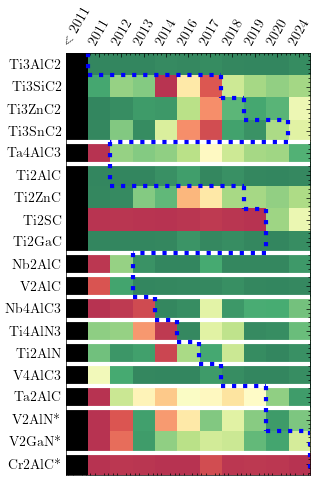

In [14]:
plot_supervised_timeline("svc")
plt.savefig("figures/timeline_validation_pumkl_svc.pdf")

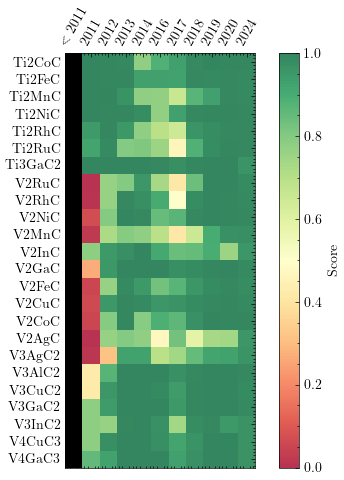

In [15]:
plot_unknown_timeline("svc", threshold=0.95)
plt.savefig("figures/timeline_validation_pumkl_extra_compounds_svc.pdf")

# Evolution of the recall depending on the positivity threshold

In [16]:
def get_all_predictions(scoring="svc"):
    all_predictions = []
    pu_labels = pd.read_csv("../data/pu_labels.csv", index_col=0)
    targets = (pu_labels["class"]>0).to_numpy().reshape(-1)
    for year in sorted(pd.unique(years_df.max_years)):
        if year==2025:
            continue
        if year==2011 and scoring=="pu":
            continue
        df = load_results(year, scoring=scoring)
        #targets = (df["Class"]>0).to_numpy().reshape(-1)
        preds = (df["Score"]).to_numpy().reshape(-1)
        all_predictions += [{"y":targets, "pred":preds}]
    return all_predictions

In [17]:
from sklearn import metrics
def plot_recall(scoring="svc", thresholds=[0.5,0.75,0.85,0.9,0.95]):
    all_predictions = get_all_predictions(scoring)
    years=sorted(pd.unique(years_df.max_years))[:-1]
    if scoring=="pu":
        years = years[1:]
    for threshold in thresholds:
        recalls = [metrics.recall_score(x["y"], x["pred"]>=threshold) for x in all_predictions]
        plt.plot(years, recalls, label=threshold)
    plt.legend()
    plt.ylim((-0.1,1.1))
    plt.xticks(ticks=years, rotation=60)
    plt.ylabel("Recall")

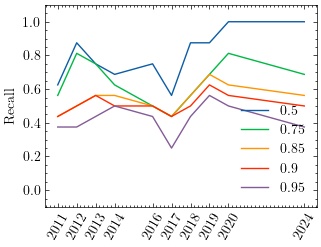

In [18]:
plot_recall("svc")

# Figures for the evolution of clustering

In [19]:
def plot_ari_evolution(clustering_model):
    root = os.path.join("..","validation","timeline","clustering")
    all_clusterings = []
    all_years = sorted([int(x) for x in os.listdir(root)])
    for year in all_years:
        if year==2025:
            continue
        df = pd.read_csv(os.path.join(root, str(year), clustering_model, f"{clustering_model}_150_clusters.csv"), index_col=0)
        all_clusterings += [df.Cluster.to_numpy().reshape(-1)]
    scores = np.zeros(len(all_clusterings)-1)
    for c in range(len(scores)):
        scores[c] = metrics.adjusted_rand_score(all_clusterings[c], all_clusterings[c+1])
    plt.plot(all_years[1:], scores)
    plt.ylim((0,1))
    plt.ylabel("ARI")
    plt.xlabel("Year")
    plt.xticks(all_years[1:], all_years[1:], rotation=60)
    plt.tight_layout()
    

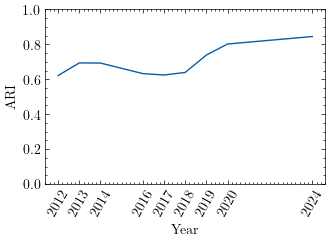

In [20]:
plot_ari_evolution("pumkl")

# Figures for the difference in recall (train / test)

In [21]:
def get_all_predictions(scoring="svc"):
    all_predictions = []
    pu_labels = pd.read_csv("../data/pu_labels.csv", index_col=0)
    all_targets = (pu_labels["class"]>0).to_numpy().reshape(-1)
    for year in sorted(pd.unique(years_df.max_years)):
        if year==2025:
            continue
        if year==2011 and scoring=="pu":
            continue
        df = load_results(year, scoring=scoring)
        y_train = (df["Class"]>0).to_numpy().reshape(-1)
        preds = (df["Score"]).to_numpy().reshape(-1)
        y_test = all_targets ^ y_train # Targets that were not part of the training set, but are part of all known targets
        all_predictions += [{"y_train":y_train, "y_test":y_test, "pred":preds, "y_all":all_targets}]
    return all_predictions

In [22]:
def plot_difference_recall(scoring="svc"):
    all_predictions = get_all_predictions(scoring)
    years=sorted(pd.unique(years_df.max_years))[:-1]
    if scoring=="pu":
        years = years[1:]
    recall_scores = [metrics.recall_score(x["y_train"], x["pred"].round()) for x in all_predictions]
    plt.plot(years, recall_scores, label="Observed MXenes", linestyle=":")
    recall_scores = [metrics.recall_score(x["y_test"], x["pred"].round(), zero_division=1) for x in all_predictions]
    plt.plot(years, recall_scores, label="Remaining MXenes", linestyle="--")
    recall_scores = [metrics.recall_score(x["y_all"], x["pred"].round()) for x in all_predictions]
    plt.plot(years, recall_scores, label="All MXenes")
    plt.legend()
    plt.ylim((0,1.1))
    plt.xticks(ticks=years, rotation=60)
    plt.ylabel("Recall")

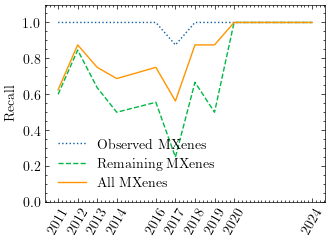

In [23]:
plot_difference_recall("svc")
plt.tight_layout()
plt.savefig("figures/timeline_recall_svc.pdf")

In [24]:
all_models = ["pumkl", "kmeans", "pckmeans", "copkmeans"]
all_clusterings = {k:dict() for k in all_models}
root = os.path.join("..","validation","timeline","clustering")
for year in sorted(os.listdir(root)):
    if year=="2025":
        continue
    for clustering_model in ["pumkl", "kmeans", "pckmeans", "copkmeans"]:
        df = pd.read_csv(os.path.join(root, year, clustering_model, f"{clustering_model}_150_clusters.csv"), index_col=0)
        all_clusterings[clustering_model][int(year)] = df.Cluster.to_numpy().reshape(-1)

In [25]:
all_years = sorted(list(all_clusterings["pumkl"].keys()))
scores = np.zeros((len(all_clusterings), len(all_years)-1))
for c in range(scores.shape[1]):
    for i, model in enumerate(all_models):
        scores[i,c] = metrics.adjusted_rand_score(all_clusterings[model][all_years[c]], all_clusterings[model][all_years[c+1]])

In [26]:
# Now, load the pu labels for some supervised metrics
pu_labels = pd.read_csv(os.path.join("..","data","pu_labels.csv"), index_col=0).to_numpy().reshape(-1)
pu_labels[pu_labels>0] = 1

In [27]:
observed_metrics = []
for method, clusterings in all_clusterings.items():
    for year, clustering in clusterings.items():
        binarised_clustering = np.zeros(len(clustering))
        binarised_clustering[clustering>0]=1
        precision = metrics.precision_score(pu_labels, binarised_clustering)
        recall = metrics.recall_score(pu_labels, binarised_clustering)
        f1 = metrics.f1_score(pu_labels, binarised_clustering)
        n_positive = binarised_clustering.sum()

        observed_metrics += [{
            "Clustering":method,
            "Year":year,
            "Precision":precision,
            "Recall":recall,
            "F1":f1,
            "n_positive":n_positive
        }]
observed_metrics = pd.DataFrame(observed_metrics)

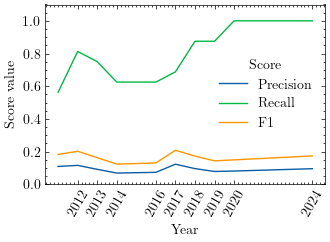

In [28]:
sns.lineplot(observed_metrics[observed_metrics.Clustering=="pumkl"].melt(id_vars="Year", value_vars=["Precision","Recall","F1"], var_name="Score"), x="Year", y="value", hue="Score")
plt.ylim((0,1.1))
plt.ylabel("Score value")
plt.xlabel("Year")
plt.xticks(all_years[1:], all_years[1:], rotation=60)
plt.tight_layout()
plt.savefig("timeline_observed_scores.pdf")